# Modelado - House Pricing

**Autor:** Roberto Farfan

Torneo de 6 modelos (regresión regularizada, ensambles y una red neuronal) para predecir `SalePrice`. Cada modelo se optimiza con `GridSearchCV` y validación cruzada K-Fold (k = 10), y el ganador se elige comparando su desempeño en el set de validación con el RMSE real (en dólares) y el RMSE normalizado al rango.

**Cómo se evita la fuga de datos:** el pipeline de features del notebook `2.0-rf-feature-engineering` se usa como una copia **sin ajustar** dentro de cada modelo, así que en cada fold de la validación cruzada las imputaciones, los límites de outliers, las transformaciones y el escalado se calculan solo con los datos de entrenamiento de ese fold. El set de validación no se usa hasta la comparación final.

**Seguimiento con MLflow:** cada ejecución del notebook crea en el experimento `house_pricing-entrenamiento` un run de torneo con nombre `torneo_AAAAMMDD_HHMMSS` (fecha y hora de la ejecución). Dentro de él queda un run por cada modelo y, dentro de cada modelo, un run por cada configuración probada. Al final, los 3 mejores modelos se registran en el Model Registry como `house_pricing`: el primero con el alias `champion` y los dos siguientes como `challenger_1` y `challenger_2`.

In [1]:
%load_ext autoreload
%autoreload 2

In [2]:
import joblib
import matplotlib.pyplot as plt
import mlflow
from mlflow import MlflowClient
from mlflow.models import infer_signature
from mlflow.types import ColSpec, Schema
import numpy as np
import pandas as pd
import seaborn as sns
from sklearn.base import clone
from sklearn.compose import TransformedTargetRegressor
from sklearn.ensemble import GradientBoostingRegressor, RandomForestRegressor
from sklearn.linear_model import ElasticNet, Lasso, Ridge
from sklearn.metrics import make_scorer, root_mean_squared_error
from sklearn.model_selection import GridSearchCV, KFold, train_test_split
from sklearn.neural_network import MLPRegressor
from sklearn.pipeline import Pipeline
from sklearn.preprocessing import StandardScaler
import yaml

from house_pricing.config import (
    MLFLOW_EXPERIMENT_ENTRENAMIENTO,
    MLFLOW_MODEL_NAME,
    MODELS_DIR,
    PROCESSED_DATA_DIR,
    PROJ_ROOT,
    RAW_DATA_DIR,
)
from house_pricing.tracking import configurar_mlflow

c:\Users\rfarfan\AppData\Local\anaconda3\envs\env_house_pricing\Lib\site-packages\tqdm\auto.py:21: TqdmWarning: IProgress not found. Please update jupyter and ipywidgets. See https://ipywidgets.readthedocs.io/en/stable/user_install.html
  from .autonotebook import tqdm as notebook_tqdm
2026-11-10 20:14:42.289 | INFO     | house_pricing.config:<module>:12 - PROJ_ROOT path is: C:\Users\rfarfan\OneDrive - Universidad Galileo\2026T4\Product Development\Ejercicios Clase\House_Pricing


## Carga de datos y división

Reproduce exactamente la división del notebook 2.0: elimina las 2 casas con `GrLivArea > 4000` y `SalePrice < 300000`, transforma el target con `log1p` y divide 80/20 con `random_state=42`. Se parte de los datos crudos (y no de `data/processed`) para que el pipeline de features se pueda reajustar dentro de cada fold. Al final se verifica que el set de validación coincide con el guardado en `data/processed`.

In [3]:
target = "SalePrice"

train = pd.read_csv(RAW_DATA_DIR / "train.csv", index_col="Id")
with open(PROJ_ROOT / "pipeline_config.yaml", encoding="utf-8") as f:
    model_features = yaml.safe_load(f)["MODEL_FEATURES"]

mask_outliers = (train["GrLivArea"] > 4000) & (train[target] < 300000)
train = train.loc[~mask_outliers]

X = train[model_features]
y = np.log1p(train[target]).rename("SalePrice_log")
X_train, X_val, y_train, y_val = train_test_split(X, y, test_size=0.2, random_state=42)

# Verifica que la división es la misma del notebook 2.0
y_val_guardado = pd.read_csv(PROCESSED_DATA_DIR / "y_val.csv", index_col="Id")["SalePrice_log"]
assert X_val.index.equals(y_val_guardado.index), "El set de validación no coincide con el del notebook 2.0"

print(f"X_train: {X_train.shape} | X_val: {X_val.shape}")

X_train: (1166, 30) | X_val: (292, 30)


## Pipeline de features, métrica y validación cruzada

- **Pipeline de features:** `clone` del pipeline guardado en `models/pipeline_fe.joblib` devuelve una copia con la misma configuración pero sin ajustar, que se vuelve a ajustar en cada fold.
- **Métrica:** RMSE real en dólares. Los modelos se entrenan con `SalePrice_log`, así que las predicciones se regresan a dólares con `expm1` antes de calcular el error. Las predicciones en escala log se limitan a [0, 15] para que una predicción extrema no desborde `expm1`.
- **RMSE normalizado al rango:** `RMSE real / (máx − mín de SalePrice en validación)`.
- **Validación cruzada:** K-Fold con k = 10, con mezcla aleatoria y semilla fija.

In [4]:
pipeline_fe = joblib.load(MODELS_DIR / "pipeline_fe.joblib")


def a_dolares(y_log):
    return np.expm1(np.clip(y_log, 0, 15))


def rmse_real(y_log_true, y_log_pred):
    return root_mean_squared_error(a_dolares(y_log_true), a_dolares(y_log_pred))


scorer_rmse_real = make_scorer(rmse_real, greater_is_better=False)
kfold = KFold(n_splits=10, shuffle=True, random_state=42)

precio_val = a_dolares(y_val)
rango_val = precio_val.max() - precio_val.min()
print(f"Rango de SalePrice en validación: {rango_val:,.0f}")

Rango de SalePrice en validación: 416,639


## Configuración de MLflow

Conecta MLflow a la base local `mlflow.db` (tracking y Model Registry) y guarda los artefactos en `mlruns/`, ambos en la raíz del proyecto y fuera de git. Activa el experimento `house_pricing-entrenamiento` y abre el **run del torneo**, que agrupa todo lo que se registra en esta ejecución:

```
torneo_AAAAMMDD_HHMMSS          <- fecha y hora de la ejecución
├── Ridge, Lasso, ..., MLP      <- un run por modelo
│   └── Ridge-01, Ridge-02, ... <- un run por configuración de la grilla
```

El run del torneo queda abierto hasta la sección final del notebook, donde se le agregan la tabla comparativa, las gráficas y los modelos elegidos. Guarda como parámetros los folds de la CV, la semilla y el tamaño de los sets. El identificador del torneo también se pone como tag `torneo` en todos los runs. Si una ejecución anterior quedó a medias con un run abierto, se cierra como `KILLED` antes de empezar.

Para ver los resultados, desde la raíz del proyecto:

```
mlflow ui --backend-store-uri sqlite:///mlflow.db
```

y abrir http://127.0.0.1:5000.

In [5]:
experimento_id = configurar_mlflow(MLFLOW_EXPERIMENT_ENTRENAMIENTO)
torneo_id = pd.Timestamp.now().strftime("%Y%m%d_%H%M%S")

if mlflow.active_run() is not None:
    mlflow.end_run(status="KILLED")

run_torneo = mlflow.start_run(run_name=f"torneo_{torneo_id}", tags={"torneo": torneo_id})
mlflow.log_params({
    "cv_folds": kfold.n_splits,
    "semilla": 42,
    "casas_train": len(X_train),
    "casas_val": len(X_val),
})

print(f"Tracking URI: {mlflow.get_tracking_uri()}")
print(f"Experimento: {MLFLOW_EXPERIMENT_ENTRENAMIENTO} (id {experimento_id})")
print(f"Run del torneo: torneo_{torneo_id} ({run_torneo.info.run_id})")

2026-11-10 20:14:43.930 | INFO     | house_pricing.tracking:configurar_mlflow:31 - MLflow: sqlite:///C:/Users/rfarfan/OneDrive - Universidad Galileo/2026T4/Product Development/Ejercicios Clase/House_Pricing/mlflow.db | experimento house_pricing-entrenamiento (id 1)
Tracking URI: sqlite:///C:/Users/rfarfan/OneDrive - Universidad Galileo/2026T4/Product Development/Ejercicios Clase/House_Pricing/mlflow.db
Experimento: house_pricing-entrenamiento (id 1)
Run del torneo: torneo_20261110_201443 (151b069d66d64867b1794cf4e6fed2a9)


## Función de entrenamiento y evaluación

`entrenar_modelo` arma el pipeline completo (features + modelo), ejecuta `GridSearchCV` con K-Fold k = 10 y, con la mejor configuración (reentrenada con todo el set de entrenamiento), calcula:

- **RMSE de entrenamiento:** error sobre los mismos datos con que se entrenó.
- **RMSE de CV:** media y desviación estándar en los 10 folds.
- **RMSE de validación y RMSE normalizado:** error sobre datos que el modelo nunca vio.

Una brecha grande entre el RMSE de entrenamiento y el de CV o validación indica sobreajuste.

**Registro en MLflow:** cada llamada crea, dentro del run del torneo, un run con el nombre del modelo que guarda:

- **Parámetros:** el estimador, el número de configuraciones, los folds de CV y los mejores hiperparámetros.
- **Métricas:** RMSE de entrenamiento, RMSE de CV (media y desviación), RMSE y NRMSE de validación, y la brecha entre entrenamiento y CV.
- **Artefactos:** `diagnostico.png` (predicho vs real, residuos y RMSE por fold) y `configuraciones.csv` con todas las configuraciones probadas.

Dentro de ese run se crea un run hijo por cada configuración de la grilla, con sus hiperparámetros, su RMSE de CV (media y desviación), su posición en la búsqueda y su tiempo promedio de entrenamiento por fold.

In [6]:
resultados = {}


def sin_prefijo(params):
    """Quita el prefijo del paso del pipeline: modelo__regressor__alpha -> alpha."""
    return {clave.split("__")[-1]: valor for clave, valor in params.items()}


def figura_diagnostico(nombre, pred_val, rmse_folds):
    """Predicho vs real y residuos en validación, y RMSE por fold de la CV."""
    residuos = precio_val - pred_val
    limites = [precio_val.min(), precio_val.max()]
    fig, axes = plt.subplots(1, 3, figsize=(18, 5))

    axes[0].scatter(precio_val, pred_val, alpha=0.5, s=12)
    axes[0].plot(limites, limites, color="red", linestyle="--")
    axes[0].set(title="Predicho vs real (validación)", xlabel="SalePrice real", ylabel="SalePrice predicho")

    axes[1].scatter(pred_val, residuos, alpha=0.5, s=12)
    axes[1].axhline(0, color="red", linestyle="--")
    axes[1].set(title="Residuos (validación)", xlabel="SalePrice predicho", ylabel="Real - predicho")

    axes[2].bar(range(1, len(rmse_folds) + 1), rmse_folds, color="steelblue")
    axes[2].axhline(rmse_folds.mean(), color="red", linestyle="--", label="Media")
    axes[2].set(title="RMSE por fold (CV k=10)", xlabel="Fold", ylabel="RMSE (USD)")
    axes[2].legend()

    fig.suptitle(nombre)
    fig.tight_layout()
    plt.close(fig)
    return fig


def registrar_en_mlflow(nombre, modelo, busqueda, configs):
    """Run del modelo con sus métricas y artefactos, y un run hijo por configuración."""
    r = resultados[nombre]
    cv = busqueda.cv_results_
    tags = {"torneo": torneo_id, "modelo": nombre}

    with mlflow.start_run(run_name=nombre, nested=True, tags=tags) as run:
        mlflow.log_params({
            "estimador": type(getattr(modelo, "regressor", modelo)).__name__,
            "configuraciones": len(configs),
            "cv_folds": kfold.n_splits,
            **sin_prefijo(busqueda.best_params_),
        })
        mlflow.log_metrics({
            "rmse_train": r["rmse_train"],
            "rmse_cv": r["rmse_cv"],
            "rmse_cv_std": r["rmse_cv_std"],
            "rmse_val": r["rmse_val"],
            "nrmse_val": r["nrmse_val"],
            "brecha_train_cv": (r["rmse_cv"] - r["rmse_train"]) / r["rmse_cv"],
        })
        mlflow.log_figure(figura_diagnostico(nombre, r["pred_val"], r["rmse_folds"]), "diagnostico.png")
        mlflow.log_text(configs.to_csv(index=False), "configuraciones.csv")

        for i, params in enumerate(cv["params"]):
            with mlflow.start_run(run_name=f"{nombre}-{i + 1:02d}", nested=True, tags=tags):
                mlflow.log_params(sin_prefijo(params))
                mlflow.log_metrics({
                    "rmse_cv": -cv["mean_test_score"][i],
                    "rmse_cv_std": cv["std_test_score"][i],
                    "rank": cv["rank_test_score"][i],
                    "fit_time_s": cv["mean_fit_time"][i],
                })

    r["run_id"] = run.info.run_id


def entrenar_modelo(nombre, modelo, grilla):
    pipeline = Pipeline([("features", clone(pipeline_fe)), ("modelo", modelo)])
    busqueda = GridSearchCV(pipeline, grilla, scoring=scorer_rmse_real, cv=kfold, n_jobs=-1)
    busqueda.fit(X_train, y_train)

    mejor = busqueda.best_estimator_
    idx = busqueda.best_index_
    rmse_folds = np.array([-busqueda.cv_results_[f"split{i}_test_score"][idx] for i in range(kfold.n_splits)])
    pred_val = mejor.predict(X_val)
    rmse_val = rmse_real(y_val, pred_val)

    resultados[nombre] = {
        "busqueda": busqueda,
        "pred_val": a_dolares(pred_val),
        "rmse_folds": rmse_folds,
        "rmse_train": rmse_real(y_train, mejor.predict(X_train)),
        "rmse_cv": rmse_folds.mean(),
        "rmse_cv_std": rmse_folds.std(),
        "rmse_val": rmse_val,
        "nrmse_val": rmse_val / rango_val,
    }

    configs = pd.DataFrame(busqueda.cv_results_["params"])
    configs["rmse_cv"] = -busqueda.cv_results_["mean_test_score"]
    configs["rmse_cv_std"] = busqueda.cv_results_["std_test_score"]
    registrar_en_mlflow(nombre, modelo, busqueda, configs)

    print(f"{nombre}: {len(configs)} configuraciones probadas | run de MLflow: {resultados[nombre]['run_id']}")
    print(f"Mejor configuración: {busqueda.best_params_}")
    print(
        f"RMSE train: {resultados[nombre]['rmse_train']:,.0f} | "
        f"RMSE CV: {resultados[nombre]['rmse_cv']:,.0f} ± {resultados[nombre]['rmse_cv_std']:,.0f} | "
        f"RMSE val: {rmse_val:,.0f} | NRMSE val: {resultados[nombre]['nrmse_val']:.4f}"
    )
    return configs.sort_values("rmse_cv").round(4)

## Modelo 1: Ridge

Regresión lineal con regularización L2: reduce los coeficientes para que el modelo no dependa demasiado de una sola variable. Se busca la fuerza de regularización `alpha`.

In [7]:
entrenar_modelo(
    "Ridge",
    Ridge(),
    {"modelo__alpha": [0.1, 1, 3, 10, 30, 100]},
)

Ridge: 6 configuraciones probadas | run de MLflow: f3a1e01adab2460da4dba4923df036b4
Mejor configuración: {'modelo__alpha': 30}
RMSE train: 25,180 | RMSE CV: 25,705 ± 4,622 | RMSE val: 23,652 | NRMSE val: 0.0568


,modelo__alpha,rmse_cv,rmse_cv_std
4,30.0,25705.4278,4621.8206
3,10.0,25720.5760,4603.5265
2,3.0,25739.8804,4605.0989
1,1.0,25747.2623,4606.5939
0,0.1,25750.8924,4607.4379
5,100.0,25855.6328,4802.3533


## Modelo 2: Lasso

Regresión lineal con regularización L1: además de reducir coeficientes, puede llevar algunos a cero, lo que funciona como selección de variables. Se busca `alpha`.

In [8]:
entrenar_modelo(
    "Lasso",
    Lasso(max_iter=50000),
    {"modelo__alpha": [0.0001, 0.0003, 0.001, 0.003, 0.01]},
)

Lasso: 5 configuraciones probadas | run de MLflow: 4cc3992d5d474d968110c6b992cf6be2
Mejor configuración: {'modelo__alpha': 0.0001}
RMSE train: 25,185 | RMSE CV: 25,759 ± 4,622 | RMSE val: 23,565 | NRMSE val: 0.0566


,modelo__alpha,rmse_cv,rmse_cv_std
0,0.0001,25759.0711,4621.9121
1,0.0003,25777.0039,4651.7491
2,0.0010,25847.7619,4756.2134
3,0.0030,26021.8684,5011.6722
4,0.0100,26745.1749,5839.2460


## Modelo 3: ElasticNet

Combina las regularizaciones L1 y L2. Se busca la fuerza total (`alpha`) y la proporción de L1 (`l1_ratio`).

In [9]:
entrenar_modelo(
    "ElasticNet",
    ElasticNet(max_iter=50000),
    {
        "modelo__alpha": [0.0001, 0.001, 0.01],
        "modelo__l1_ratio": [0.2, 0.5, 0.8],
    },
)

ElasticNet: 9 configuraciones probadas | run de MLflow: 041dfff065834e09a8fb3a027f9fe9e8
Mejor configuración: {'modelo__alpha': 0.0001, 'modelo__l1_ratio': 0.2}
RMSE train: 25,176 | RMSE CV: 25,753 ± 4,610 | RMSE val: 23,585 | NRMSE val: 0.0566


,modelo__alpha,modelo__l1_ratio,rmse_cv,rmse_cv_std
0,0.0001,0.2,25752.5252,4610.3666
1,0.0001,0.5,25755.0014,4614.8616
2,0.0001,0.8,25757.4912,4619.2881
3,0.0010,0.2,25764.4526,4636.1492
4,0.0010,0.5,25794.0491,4681.6486
5,0.0010,0.8,25826.8804,4726.0222
6,0.0100,0.2,25891.8991,4879.5989
7,0.0100,0.5,26215.1219,5226.2291
8,0.0100,0.8,26527.8591,5600.0388


## Modelo 4: Random Forest

Ensamble de árboles de decisión entrenados en paralelo sobre muestras aleatorias; la predicción es el promedio de los árboles. Se busca la profundidad máxima, el mínimo de casas por hoja y la proporción de variables que considera cada división (valores más restrictivos reducen el sobreajuste).

In [10]:
entrenar_modelo(
    "RandomForest",
    RandomForestRegressor(n_estimators=300, random_state=42),
    {
        "modelo__max_depth": [None, 15],
        "modelo__min_samples_leaf": [1, 3],
        "modelo__max_features": [0.33, 1.0],
    },
)

RandomForest: 8 configuraciones probadas | run de MLflow: 5a02c1bc8ed9469aacc1d63b1e1d0bf6
Mejor configuración: {'modelo__max_depth': None, 'modelo__max_features': 0.33, 'modelo__min_samples_leaf': 1}
RMSE train: 10,546 | RMSE CV: 26,716 ± 4,787 | RMSE val: 24,232 | NRMSE val: 0.0582


,modelo__max_depth,modelo__max_features,modelo__min_samples_leaf,rmse_cv,rmse_cv_std
0,NaN,0.33,1,26715.6514,4787.4166
4,15.0,0.33,1,26832.8442,4908.9730
6,15.0,1.00,1,27547.6458,4425.2849
2,NaN,1.00,1,27560.7838,4420.2588
1,NaN,0.33,3,27833.2941,6012.5833
5,15.0,0.33,3,27889.3318,6090.2184
3,NaN,1.00,3,28183.3250,5364.5568
7,15.0,1.00,3,28188.1871,5357.8166


## Modelo 5: Gradient Boosting

Ensamble de árboles entrenados en secuencia, donde cada árbol corrige los errores de los anteriores. Se busca el número de árboles, la tasa de aprendizaje y la profundidad; `subsample=0.8` entrena cada árbol con el 80 % de los datos para reducir el sobreajuste.

In [11]:
entrenar_modelo(
    "GradientBoosting",
    GradientBoostingRegressor(subsample=0.8, random_state=42),
    {
        "modelo__n_estimators": [300, 600],
        "modelo__learning_rate": [0.03, 0.1],
        "modelo__max_depth": [2, 3],
    },
)

GradientBoosting: 8 configuraciones probadas | run de MLflow: f123d3c2dc3c44f7a1b729dce241ef8b
Mejor configuración: {'modelo__learning_rate': 0.03, 'modelo__max_depth': 3, 'modelo__n_estimators': 300}
RMSE train: 17,265 | RMSE CV: 25,338 ± 3,316 | RMSE val: 22,992 | NRMSE val: 0.0552


,modelo__learning_rate,modelo__max_depth,modelo__n_estimators,rmse_cv,rmse_cv_std
2,0.03,3,300,25338.0387,3315.6725
3,0.03,3,600,25472.6873,3492.3138
1,0.03,2,600,25508.4638,3385.7903
0,0.03,2,300,26185.3685,3736.6742
4,0.10,2,300,26191.5199,3830.8010
6,0.10,3,300,26751.8680,3816.4923
5,0.10,2,600,26832.8770,4137.5433
7,0.10,3,600,27233.0159,3872.2195


## Modelo 6: Red neuronal (MLPRegressor)

Perceptrón multicapa. Se busca la arquitectura (capas ocultas y neuronas) y la regularización L2 (`alpha`). Para evitar sobreajuste usa `early_stopping`: separa el 10 % de los datos de entrenamiento del fold y detiene el entrenamiento cuando el error en esa parte deja de mejorar. El target se estandariza dentro del modelo (`TransformedTargetRegressor`), porque las redes neuronales entrenan mejor con salidas cercanas a 0.

In [12]:
entrenar_modelo(
    "MLP",
    TransformedTargetRegressor(
        regressor=MLPRegressor(max_iter=2000, early_stopping=True, random_state=42),
        transformer=StandardScaler(),
    ),
    {
        "modelo__regressor__hidden_layer_sizes": [(64,), (64, 32), (128, 64)],
        "modelo__regressor__alpha": [0.001, 0.1],
    },
)

MLP: 6 configuraciones probadas | run de MLflow: 8ccf5f38b82f4bf283b0c9aacb60c88b
Mejor configuración: {'modelo__regressor__alpha': 0.1, 'modelo__regressor__hidden_layer_sizes': (128, 64)}
RMSE train: 15,350 | RMSE CV: 26,533 ± 3,046 | RMSE val: 24,016 | NRMSE val: 0.0576


,modelo__regressor__alpha,modelo__regressor__hidden_layer_sizes,rmse_cv,rmse_cv_std
5,0.100,"(128, 64)",26533.4969,3045.8326
2,0.001,"(128, 64)",26614.6965,3171.5430
3,0.100,"(64,)",27705.6242,4842.1928
0,0.001,"(64,)",27935.1409,4777.5133
4,0.100,"(64, 32)",27939.2320,3515.3198
1,0.001,"(64, 32)",28287.8056,3368.1296


## Resultados del torneo

Tabla comparativa de los 6 modelos con su mejor configuración, ordenada por RMSE en validación. La columna `brecha_train_cv` es la diferencia relativa entre el error de CV y el de entrenamiento: valores altos indican sobreajuste.

In [13]:
tabla = pd.DataFrame({
    nombre: {
        "rmse_train": r["rmse_train"],
        "rmse_cv": r["rmse_cv"],
        "rmse_cv_std": r["rmse_cv_std"],
        "rmse_val": r["rmse_val"],
        "nrmse_val": r["nrmse_val"],
    }
    for nombre, r in resultados.items()
}).T
tabla["brecha_train_cv"] = (tabla["rmse_cv"] - tabla["rmse_train"]) / tabla["rmse_cv"]
tabla = tabla.sort_values("rmse_val")
tabla.round({
    "rmse_train": 0, "rmse_cv": 0, "rmse_cv_std": 0,
    "rmse_val": 0, "nrmse_val": 4, "brecha_train_cv": 3,
})

,rmse_train,rmse_cv,rmse_cv_std,rmse_val,nrmse_val,brecha_train_cv
GradientBoosting,17265.0,25338.0,3316.0,22992.0,0.0552,0.319
Lasso,25185.0,25759.0,4622.0,23565.0,0.0566,0.022
ElasticNet,25176.0,25753.0,4610.0,23585.0,0.0566,0.022
Ridge,25180.0,25705.0,4622.0,23652.0,0.0568,0.020
MLP,15350.0,26533.0,3046.0,24016.0,0.0576,0.421
RandomForest,10546.0,26716.0,4787.0,24232.0,0.0582,0.605


## Comparación del torneo

- **Barras:** RMSE real y RMSE normalizado al rango en el set de validación (menor es mejor).
- **Boxplot:** RMSE de los 10 folds de la validación cruzada para la mejor configuración de cada modelo. Una caja angosta indica un modelo estable.

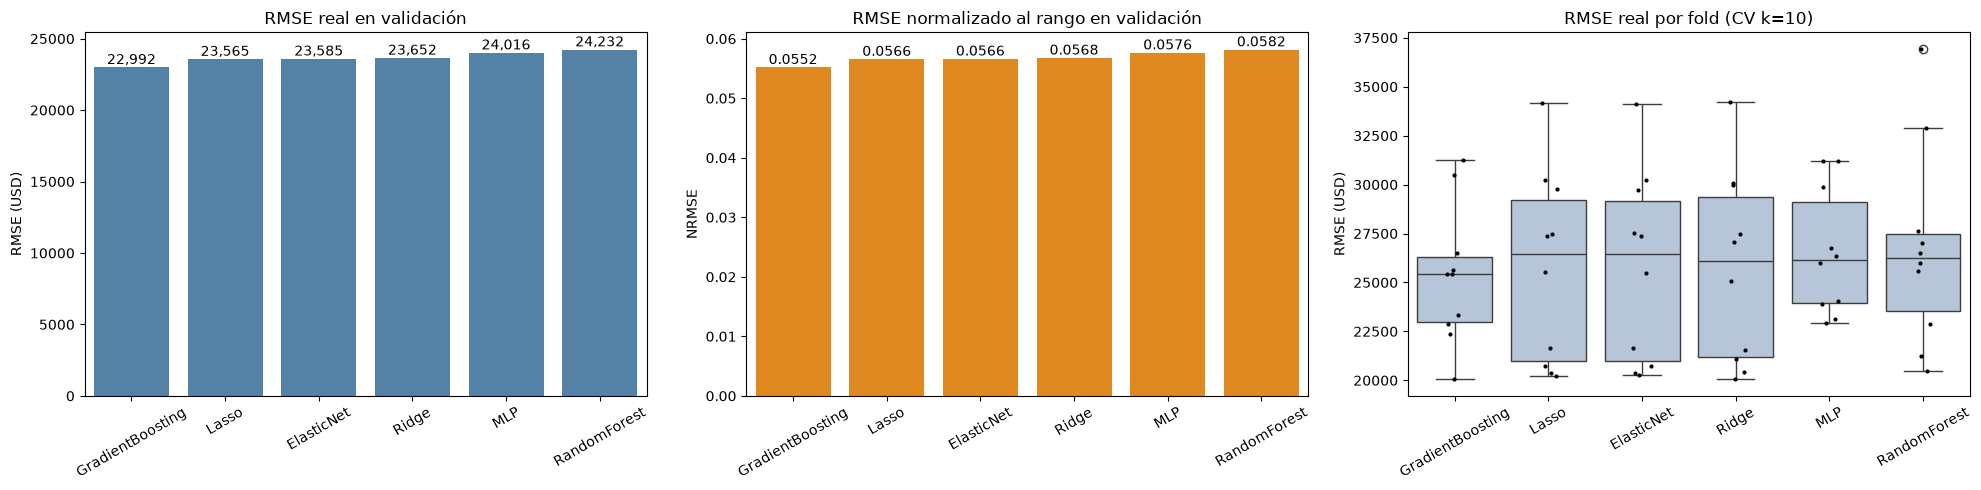

In [14]:
orden = tabla.index.tolist()

fig_comparacion, axes = plt.subplots(1, 3, figsize=(20, 5))

sns.barplot(x=orden, y=tabla["rmse_val"], ax=axes[0], color="steelblue")
axes[0].set_title("RMSE real en validación")
axes[0].set_ylabel("RMSE (USD)")
for i, v in enumerate(tabla["rmse_val"]):
    axes[0].text(i, v, f"{v:,.0f}", ha="center", va="bottom")

sns.barplot(x=orden, y=tabla["nrmse_val"], ax=axes[1], color="darkorange")
axes[1].set_title("RMSE normalizado al rango en validación")
axes[1].set_ylabel("NRMSE")
for i, v in enumerate(tabla["nrmse_val"]):
    axes[1].text(i, v, f"{v:.4f}", ha="center", va="bottom")

folds = pd.DataFrame({nombre: resultados[nombre]["rmse_folds"] for nombre in orden})
sns.boxplot(data=folds, ax=axes[2], color="lightsteelblue")
sns.stripplot(data=folds, ax=axes[2], color="black", size=3)
axes[2].set_title("RMSE real por fold (CV k=10)")
axes[2].set_ylabel("RMSE (USD)")

for ax in axes:
    ax.tick_params(axis="x", rotation=30)

plt.tight_layout()
plt.show()

## Predicho vs real en validación

Para cada modelo, compara el precio predicho con el real en el set de validación (en dólares). Los puntos sobre la línea roja (y = x) son predicciones perfectas; si se abren en abanico o se curvan, el modelo se equivoca más en ciertos rangos de precio.

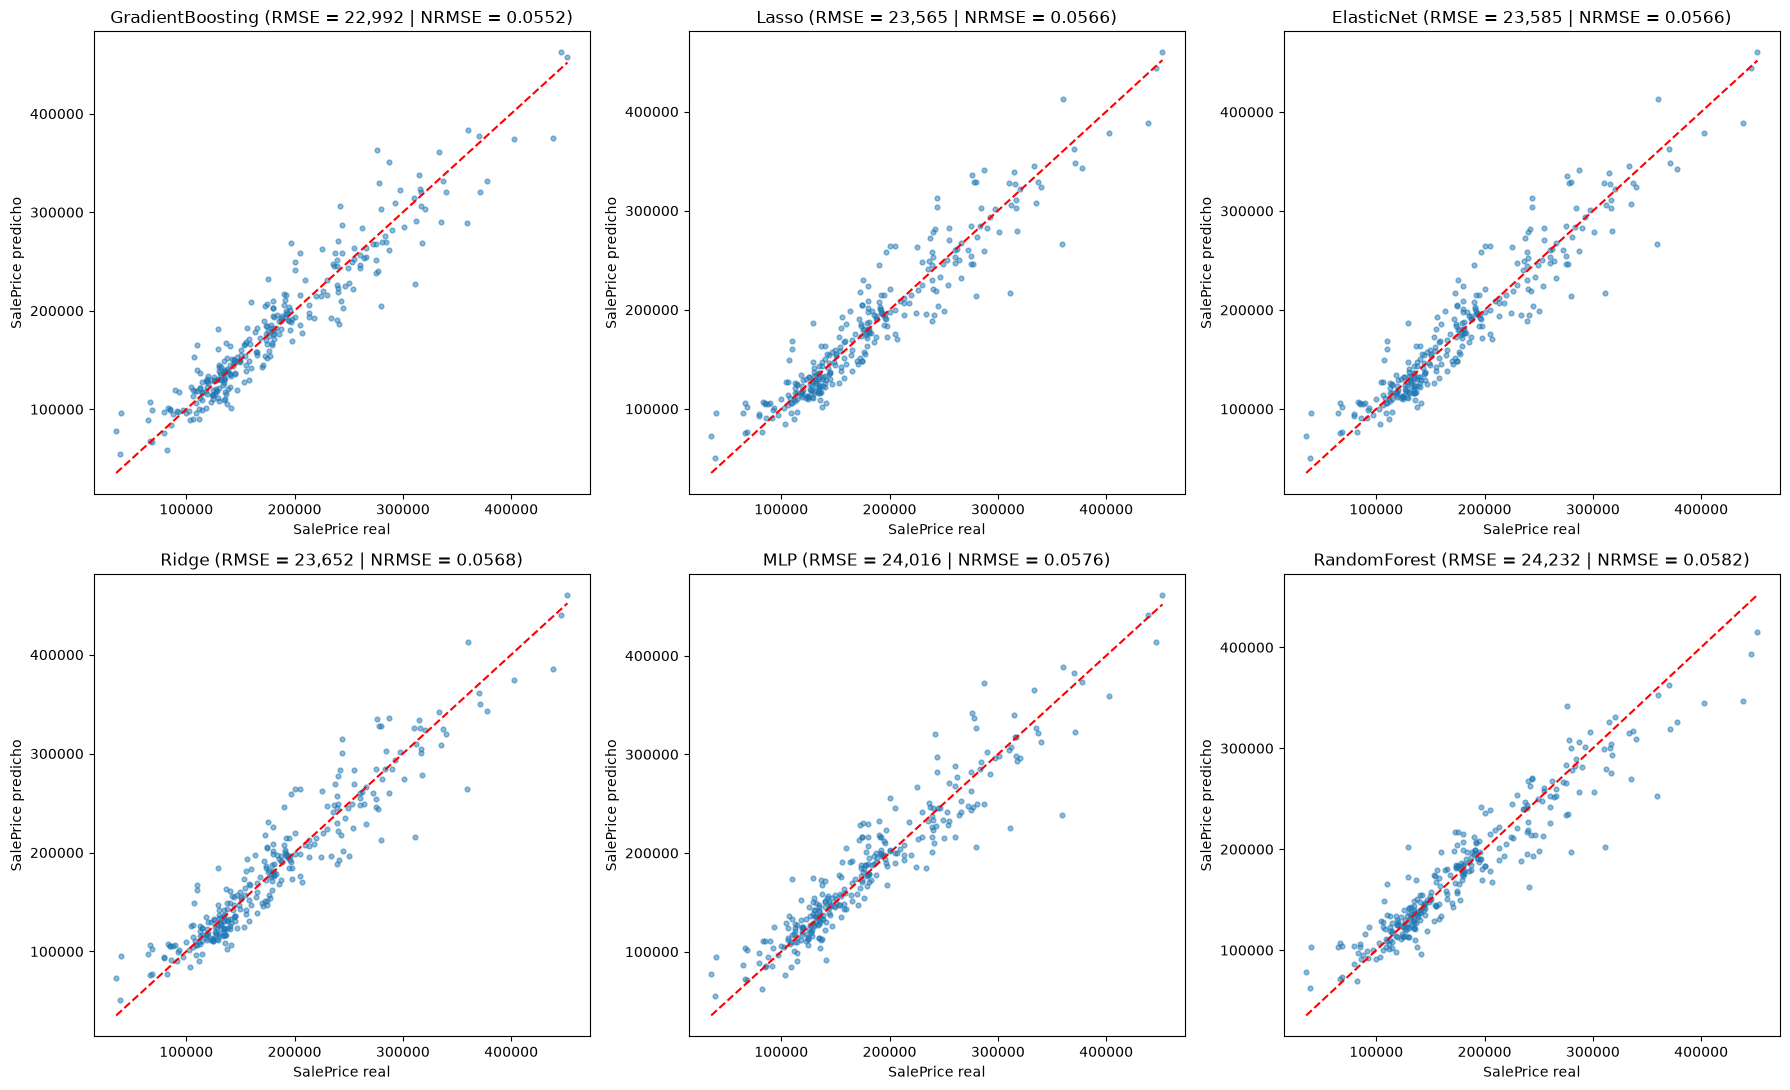

In [15]:
n_cols = 3
n_rows = int(np.ceil(len(orden) / n_cols))
fig_pred_real, axes = plt.subplots(n_rows, n_cols, figsize=(6 * n_cols, 5.5 * n_rows))
axes = axes.flatten()

limites = [precio_val.min(), precio_val.max()]
for ax, nombre in zip(axes, orden):
    r = resultados[nombre]
    ax.scatter(precio_val, r["pred_val"], alpha=0.5, s=12)
    ax.plot(limites, limites, color="red", linestyle="--")
    ax.set_title(f"{nombre} (RMSE = {r['rmse_val']:,.0f} | NRMSE = {r['nrmse_val']:.4f})")
    ax.set_xlabel("SalePrice real")
    ax.set_ylabel("SalePrice predicho")

for ax in axes[len(orden):]:
    ax.set_visible(False)

plt.tight_layout()
plt.show()

## Modelo ganador

Selecciona el modelo con menor RMSE real en validación y guarda su pipeline completo (features + modelo, entrenado con el set de entrenamiento) en `models/` para usarlo en las predicciones.

In [16]:
ganador = tabla.index[0]
modelo_ganador = resultados[ganador]["busqueda"].best_estimator_

print(f"Modelo ganador: {ganador}")
print(f"Configuración: {resultados[ganador]['busqueda'].best_params_}")
print(f"RMSE val: {tabla.loc[ganador, 'rmse_val']:,.0f} | NRMSE val: {tabla.loc[ganador, 'nrmse_val']:.4f}")

ruta_modelo = MODELS_DIR / "modelo_ganador.joblib"
joblib.dump(modelo_ganador, ruta_modelo)
print(f"Guardado en: {ruta_modelo}")

Modelo ganador: GradientBoosting
Configuración: {'modelo__learning_rate': 0.03, 'modelo__max_depth': 3, 'modelo__n_estimators': 300}
RMSE val: 22,992 | NRMSE val: 0.0552
Guardado en: C:\Users\rfarfan\OneDrive - Universidad Galileo\2026T4\Product Development\Ejercicios Clase\House_Pricing\models\modelo_ganador.joblib


## Pipeline de inferencia

Arma el pipeline final que recibe los datos **crudos** y devuelve el precio **en dólares**:

1. `seleccion`: toma solo las columnas de `MODEL_FEATURES` del CSV crudo.
2. `features`: el pipeline de ingeniería de características del notebook 2.0 (imputación, codificación, outliers, Yeo-Johnson y escalado).
3. `modelo`: el modelo con los hiperparámetros ganadores del torneo.
4. `TransformedTargetRegressor`: aplica `log1p` al target al entrenar y `expm1` a las predicciones, para que la salida quede en dólares.

Como el modelo ya se eligió, el pipeline se reentrena con **todos** los datos de `train.csv` (entrenamiento + validación, sin las 2 casas atípicas) para aprovechar más información. No hay fuga de datos, porque `test.csv` no se usa en el entrenamiento. El del ganador se guarda en `models/pipeline_inferencia.joblib`, que es el que usa `scripts/inferencia.py`. La función `construir_pipeline_inferencia` se reutiliza en la siguiente sección para los challengers.

In [17]:
from operator import itemgetter

from sklearn.preprocessing import FunctionTransformer

# Todos los datos de train.csv (sin las 2 casas atípicas), con el target en dólares
X_completo = train.drop(columns=target)
y_completo = train[target]


def construir_pipeline_inferencia(nombre):
    """Pipeline de datos crudos a dólares con el mejor modelo de `nombre`, reentrenado con X_completo."""
    modelo = resultados[nombre]["busqueda"].best_estimator_.named_steps["modelo"]
    pipeline = TransformedTargetRegressor(
        regressor=Pipeline([
            ("seleccion", FunctionTransformer(itemgetter(model_features))),
            ("features", clone(pipeline_fe)),
            ("modelo", clone(modelo)),
        ]),
        func=np.log1p,
        inverse_func=np.expm1,
    )
    return pipeline.fit(X_completo, y_completo)


pipeline_inferencia = construir_pipeline_inferencia(ganador)

print(f"Entrenado con {len(X_completo)} casas")
print(f"Hiperparámetros del modelo: {pipeline_inferencia.regressor_.named_steps['modelo'].get_params()}")

ruta_inferencia = MODELS_DIR / "pipeline_inferencia.joblib"
joblib.dump(pipeline_inferencia, ruta_inferencia)
print(f"Guardado en: {ruta_inferencia}")

pipeline_inferencia

Entrenado con 1458 casas
Hiperparámetros del modelo: {'alpha': 0.9, 'ccp_alpha': 0.0, 'criterion': 'deprecated', 'init': None, 'learning_rate': 0.03, 'loss': 'squared_error', 'max_depth': 3, 'max_features': None, 'max_leaf_nodes': None, 'min_impurity_decrease': 0.0, 'min_samples_leaf': 1, 'min_samples_split': 2, 'min_weight_fraction_leaf': 0.0, 'n_estimators': 300, 'n_iter_no_change': None, 'random_state': 42, 'subsample': 0.8, 'tol': 0.0001, 'validation_fraction': 0.1, 'verbose': 0, 'warm_start': False}
Guardado en: C:\Users\rfarfan\OneDrive - Universidad Galileo\2026T4\Product Development\Ejercicios Clase\House_Pricing\models\pipeline_inferencia.joblib


,"regressor regressor: object, default=NoneRegressor object such as derived from:class:`~sklearn.base.RegressorMixin`. This regressor willautomatically be cloned each time prior to fitting. If `regressor isNone`, :class:`~sklearn.linear_model.LinearRegression` is created and used.",Pipeline(step...sample=0.8))])
,"func func: function, default=NoneFunction to apply to `y` before passing to :meth:`fit`. Cannot be setat the same time as `transformer`. If `func is None`, the function used will bethe identity function. If `func` is set, `inverse_func` also needs to beprovided. The function needs to return a 2-dimensional array.",<ufunc 'log1p'>
,"inverse_func inverse_func: function, default=NoneFunction to apply to the prediction of the regressor. Cannot be set atthe same time as `transformer`. The inverse function is used to returnpredictions to the same space of the original training labels. If`inverse_func` is set, `func` also needs to be provided. The inversefunction needs to return a 2-dimensional array.",<ufunc 'expm1'>
,"transformer transformer: object, default=NoneEstimator object such as derived from:class:`~sklearn.base.TransformerMixin`. Cannot be set at the same timeas `func` and `inverse_func`. If `transformer is None` as well as`func` and `inverse_func`, the transformer will be an identitytransformer. Note that the transformer will be cloned during fitting.Also, the transformer is restricting `y` to be a numpy array.",None
,"check_inverse check_inverse: bool, default=TrueWhether to check that `transform` followed by `inverse_transform`or `func` followed by `inverse_func` leads to the original targets.",True
Name,Type,Value
"feature_names_in_ feature_names_in_: ndarray of shape (`n_features_in_`,)Names of features seen during :term:`fit`. Defined only when `X`has feature names that are all strings... versionadded:: 1.0","ndarray[object](79,)","['MSSubClass','MSZoning','LotFrontage',...,'YrSold','SaleType', 'SaleCondition']"
n_features_in_ n_features_in_: intNumber of features seen during :term:`fit`. Only defined if theunderlying regressor exposes such an attribute when fit... versionadded:: 0.24,int,79
regressor_ regressor_: objectFitted regressor.,Pipeline,Pipeline(step...sample=0.8))])
transformer_ transformer_: objectTransformer used in :meth:`fit` and :meth:`predict`.,FunctionTransformer,FunctionTrans...validate=True)
,"steps steps: list of tuplesList of (name of step, estimator) tuples that are to be chained insequential order. To be compatible with the scikit-learn API, all stepsmust define `fit`. All non-last steps must also define `transform`. See:ref:`Combining Estimators <combining_estimators>` for more details.","[('seleccion', ...), ('features', ...), ...]"


## Registro en MLflow: champion y challengers

Registra los 3 mejores modelos del torneo (por RMSE en validación) como versiones del modelo `house_pricing` en el Model Registry:

| Posición | Alias |
|---|---|
| 1 | `champion` |
| 2 | `challenger_1` |
| 3 | `challenger_2` |

- **Qué se registra:** el pipeline de inferencia completo (datos crudos a dólares), reentrenado con las 1,458 casas de `train.csv`. El del champion es el mismo objeto que se guardó en `models/pipeline_inferencia.joblib`.
- **Dónde se registra:** cada pipeline se guarda dentro del run de su modelo (que está dentro del run del torneo), así que la versión registrada queda ligada a las métricas de validación medidas **antes** de reentrenar. Además, cada run recibe los tags `posicion` y `rol`, y se registra el número de casas usadas para reentrenar.
- **Firma del modelo:** las 30 features de `MODEL_FEATURES` como columnas opcionales, con los numéricos como `double`, porque el pipeline imputa los faltantes y `test.csv` trae columnas enteras con valores vacíos.
- **Serialización:** `cloudpickle`. El formato por defecto de MLflow 3 (`skops`) no puede guardar el estado interno de feature-engine.

Si el notebook se vuelve a correr, se crean versiones nuevas y los aliases se mueven a ellas; las versiones anteriores quedan en el historial.

In [18]:
client = MlflowClient()
roles = ["champion", "challenger_1", "challenger_2"]

for posicion, nombre in enumerate(tabla.index, start=1):
    client.set_tag(resultados[nombre]["run_id"], "posicion", posicion)

ejemplo = X_completo[model_features].head(5)
ejemplo = ejemplo.astype({col: "float64" for col in ejemplo.select_dtypes("number").columns})
firma = infer_signature(ejemplo, pipeline_inferencia.predict(ejemplo))
firma.inputs = Schema([ColSpec(col.type, col.name, required=False) for col in firma.inputs.inputs])

registrados = {}
for rol, nombre in zip(roles, tabla.index):
    pipeline = pipeline_inferencia if nombre == ganador else construir_pipeline_inferencia(nombre)
    with mlflow.start_run(run_id=resultados[nombre]["run_id"], nested=True):
        mlflow.set_tag("rol", rol)
        mlflow.log_param("casas_reentrenamiento", len(X_completo))
        info = mlflow.sklearn.log_model(
            pipeline,
            name="pipeline_inferencia",
            signature=firma,
            input_example=ejemplo,
            serialization_format="cloudpickle",
            registered_model_name=MLFLOW_MODEL_NAME,
        )

    version = info.registered_model_version
    client.set_registered_model_alias(MLFLOW_MODEL_NAME, rol, version)
    client.set_model_version_tag(MLFLOW_MODEL_NAME, version, "modelo", nombre)
    client.set_model_version_tag(MLFLOW_MODEL_NAME, version, "torneo", torneo_id)
    client.update_model_version(
        MLFLOW_MODEL_NAME,
        version,
        description=(
            f"{nombre} reentrenado con {len(X_completo)} casas. "
            f"RMSE val: {tabla.loc[nombre, 'rmse_val']:,.0f} | NRMSE val: {tabla.loc[nombre, 'nrmse_val']:.4f}"
        ),
    )
    registrados[rol] = {
        "modelo": nombre,
        "version": version,
        "rmse_val": tabla.loc[nombre, "rmse_val"],
        "nrmse_val": tabla.loc[nombre, "nrmse_val"],
        "run_id": resultados[nombre]["run_id"],
    }

pd.DataFrame(registrados).T.round({"rmse_val": 0, "nrmse_val": 4})

2026/11/10 20:15:15 WARNING mlflow.sklearn: Saving scikit-learn models in the pickle or cloudpickle format requires exercising caution because these formats rely on Python's object serialization mechanism, which can execute arbitrary code during deserialization. The recommended safe alternative is the 'skops' format. For more information, see: https://scikit-learn.org/stable/model_persistence.html
Registered model 'house_pricing' already exists. Creating a new version of this model...
Created version '10' of model 'house_pricing'.
2026/11/10 20:15:21 WARNING mlflow.sklearn: Saving scikit-learn models in the pickle or cloudpickle format requires exercising caution because these formats rely on Python's object serialization mechanism, which can execute arbitrary code during deserialization. The recommended safe alternative is the 'skops' format. For more information, see: https://scikit-learn.org/stable/model_persistence.html
Registered model 'house_pricing' already exists. Creating a ne

,modelo,version,rmse_val,nrmse_val,run_id
champion,GradientBoosting,10,22992.397911,0.055185,f123d3c2dc3c44f7a1b729dce241ef8b
challenger_1,Lasso,11,23564.920799,0.05656,4cc3992d5d474d968110c6b992cf6be2
challenger_2,ElasticNet,12,23584.547017,0.056607,041dfff065834e09a8fb3a027f9fe9e8


## Cierre del run del torneo

Completa el run `torneo_AAAAMMDD_HHMMSS` con el resumen de la ejecución y lo cierra:

- **Tags:** modelo `champion`, `challenger_1` y `challenger_2`, y la versión registrada de cada uno.
- **Métricas:** RMSE y NRMSE de validación del champion.
- **Artefactos:** `tabla_torneo.csv` (la tabla comparativa de los 6 modelos), `comparacion_modelos.png` y `predicho_vs_real.png`.

In [19]:
assert mlflow.active_run().info.run_id == run_torneo.info.run_id, "El run activo no es el del torneo"

mlflow.set_tags({
    **{rol: r["modelo"] for rol, r in registrados.items()},
    **{f"version_{rol}": r["version"] for rol, r in registrados.items()},
})
mlflow.log_metrics({
    "rmse_val_champion": tabla.loc[ganador, "rmse_val"],
    "nrmse_val_champion": tabla.loc[ganador, "nrmse_val"],
})
mlflow.log_text(tabla.to_csv(index_label="modelo"), "tabla_torneo.csv")
mlflow.log_figure(fig_comparacion, "comparacion_modelos.png")
mlflow.log_figure(fig_pred_real, "predicho_vs_real.png")
mlflow.end_run()

print(f"Run del torneo cerrado: torneo_{torneo_id} ({run_torneo.info.run_id})")

Run del torneo cerrado: torneo_20261110_201443 (151b069d66d64867b1794cf4e6fed2a9)
